In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import warnings
from joblib import Parallel, delayed
from scipy.integrate import IntegrationWarning
from pthin import pthin, pcarve_ci, truncgauss_ci, normal_carving_ci
import pickle

In [2]:
# Suppress integration warnings for clean console output
warnings.filterwarnings("ignore", category=IntegrationWarning)

## Filedrawer

In [ ]:
def run_single_rep_filedrawer(mu, alpha, seed):
    """
    One replicate of the file-drawer CI comparison: unlike the winner's-curse
    setting below, each method has its own independent selection event (a
    single study is "significant at level alpha" or it isn't), so each
    method draws (rejecting non-significant studies) until it finds a
    selected one, then constructs its CI for that study. At alpha=0.05 this
    takes ~20-35 draws on average per method.
    """
    rng = np.random.default_rng(seed)
    c_alpha = norm.isf(alpha)
    res = {"p-thinning": {}, "thinning": {}, "csi": {}, "data_carving": {}}

    # --- 1. p-value thinning (Theorem) ---
    while True:
        X = rng.normal(mu, 1)
        p = norm.sf(X)
        p1, _ = pthin(p, epsilon=0.5, rng=rng)
        if p1 <= alpha:
            break
    try:
        mu_L, mu_U = pcarve_ci(
            X, theta0=0.0, a=0.0, b=alpha, epsilon=0.5, alpha=alpha,
            input_type="statistic", epsabs=1e-4, epsrel=1e-4, limit=50,
        )
    except RuntimeError:
        mu_L, mu_U = X - 50, X + 50
    res["p-thinning"]["coverage"] = (mu_L <= mu <= mu_U)
    res["p-thinning"]["width"] = (mu_U - mu_L)

    # --- 2. Data thinning (Gaussian) ---
    while True:
        X = rng.normal(mu, 1)
        W = rng.normal(0, 1)
        X1 = (X + W) / np.sqrt(2)
        X2 = (X - W) / np.sqrt(2)
        if X1 >= c_alpha:
            break
    z_alpha = norm.isf(alpha / 2)
    dt_L = np.sqrt(2) * X2 - np.sqrt(2) * z_alpha
    dt_U = np.sqrt(2) * X2 + np.sqrt(2) * z_alpha
    res["thinning"]["coverage"] = (dt_L <= mu <= dt_U)
    res["thinning"]["width"] = (dt_U - dt_L)

    # --- 3. Conditional (Truncated Gaussian) ---
    while True:
        X = rng.normal(mu, 1)
        if X >= c_alpha:
            break
    try:
        cond_L, cond_U = truncgauss_ci(X, c=c_alpha, alpha=alpha)
    except RuntimeError:
        cond_L, cond_U = X - 50, X + 50
    res["csi"]["coverage"] = (cond_L <= mu <= cond_U)
    res["csi"]["width"] = (cond_U - cond_L)

    # --- 4. Data carving ---
    # Selects on X1, as done by Gaussian data thinning,
    # but tests using the *original* X (rescaled to
    # X' = X / sqrt(2), matched to share X1's mean under mu) instead of
    # discarding its information into X2. rho = 1/sqrt(2) is Corr(X', X1)
    # -- see hypothesis_testing.ipynb's "Conditional power" section for the
    # derivation. normal_carving_ci returns a CI for the shared mean
    # E[X'] = mu/sqrt(2), so its endpoints are rescaled by sqrt(2) back to
    # the mu scale.
    while True:
        X = rng.normal(mu, 1)
        W = rng.normal(0, 1)
        X1 = (X + W) / np.sqrt(2)
        if X1 >= c_alpha:
            break
    X_nc = X / np.sqrt(2)
    sigma_x_nc = 1 / np.sqrt(2)
    rho_nc = 1 / np.sqrt(2)
    try:
        nc_L, nc_U = normal_carving_ci(
            X_nc, c=c_alpha, alpha=alpha, sigma_x=sigma_x_nc, sigma_y=1.0, rho=rho_nc,
        )
        nc_L, nc_U = np.sqrt(2) * nc_L, np.sqrt(2) * nc_U
    except RuntimeError:
        nc_L, nc_U = X - 50, X + 50
    res["data_carving"]["coverage"] = (nc_L <= mu <= nc_U)
    res["data_carving"]["width"] = (nc_U - nc_L)

    return res


def get_filedrawer_results(n_reps, mus, alpha, n_jobs=-1):
    """Parallelized evaluation using joblib, matching get_wc_results below."""
    results = {
        k: {"coverage": [], "width": []}
        for k in ["p-thinning", "thinning", "csi", "data_carving"]
    }

    ss = np.random.SeedSequence(7)
    child_seeds = ss.spawn(len(mus) * n_reps)

    seed_idx = 0
    for mu in mus:
        mu_seeds = child_seeds[seed_idx : seed_idx + n_reps]
        seed_idx += n_reps

        rep_results = Parallel(n_jobs=n_jobs)(
            delayed(run_single_rep_filedrawer)(mu, alpha, seed) for seed in mu_seeds
        )

        for k in results:
            results[k]["coverage"].append(np.mean([r[k]["coverage"] for r in rep_results]))
            results[k]["width"].append(np.mean([r[k]["width"] for r in rep_results]))

    return results

In [ ]:
# --- Simulation Parameters ---
n_reps_fd = 2000
mus_fd = np.array([0, 1, 2, 4, 8])
alpha_fd = 0.05

filedrawer_results = get_filedrawer_results(n_reps_fd, mus_fd, alpha_fd)

In [5]:
with open("../results/filedrawer_ci.pkl", "wb") as f:
    pickle.dump(filedrawer_results, f)

In [4]:
with open("../results/filedrawer_ci.pkl", 'rb') as f:
    filedrawer_results = pickle.load(f)

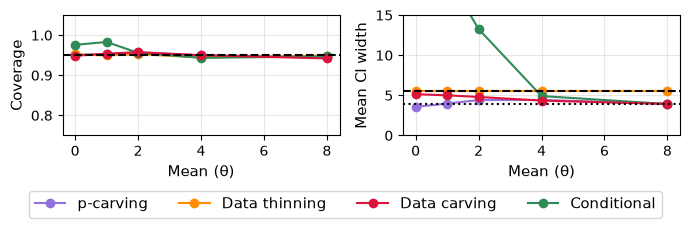

In [ ]:
# --- Plotting ---
labels_fd = {
    "p-thinning": "p-carving",
    "thinning": "Data thinning",
    "csi": "Conditional",
    "data_carving": "Data carving",
}
colors_fd = {
    "p-thinning": "mediumpurple",
    "csi": "seagreen",
    "thinning": "darkorange",
    "data_carving": "crimson",
}

fig, axes = plt.subplots(1, 2, figsize=(7, 2))

for k in filedrawer_results:
    axes[0].plot(mus_fd, filedrawer_results[k]["coverage"], marker="o", label=labels_fd[k], color=colors_fd[k])
axes[0].axhline(1 - alpha_fd, color="black", linestyle="--")
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim(0.75, 1.05)
axes[0].set_xlabel("Mean (θ)", fontsize=11)
axes[0].set_ylabel("Coverage", fontsize=11)

for k in filedrawer_results:
    axes[1].plot(mus_fd, filedrawer_results[k]["width"], marker="o", label=labels_fd[k], color=colors_fd[k])
axes[1].grid(True, alpha=0.3)
axes[1].set_xlabel("c", fontsize=11) # Mean (θ)
axes[1].set_ylabel("Mean CI width", fontsize=11)
axes[1].axhline(2 * np.sqrt(2) * 1.96, linestyle='--', color='black')
axes[1].axhline(2 * 1.96, linestyle=':', color='black')  

handles, labels = axes[0].get_legend_handles_labels()
order = [0, 1, 3, 2]
fig.legend(
    [handles[o] for o in order],
    [labels[o] for o in order],
    loc="upper center", bbox_to_anchor=(0.5, 0.06),
    ncol=4, frameon=True, fontsize=11,
)
axes[1].set_ylim([0, 15])
# axes[1].set_yscale('log')
plt.tight_layout()
plt.savefig("../figures/filedrawer_ci.png", dpi=300, bbox_inches="tight")
plt.show()

## Winner's curse

In [ ]:
def run_single_rep(mu, gap_ratio, N_total, alpha, seed):
    """
    Executes a single replication of the simulation.
    Takes a unique SeedSequence child to guarantee independent random variables.
    """
    rng = np.random.default_rng(seed)
    
    # One-Sided Upper-Tailed Test
    X = rng.normal(0, 1, size=N_total)
    X[0] += mu
    X[1] += mu * gap_ratio
    p = norm.sf(X)

    res = {"p-thinning": {}, "thinning": {}, "csi": {}, "data_carving": {}}

    # --- 1. p-value thinning (Theorem) ---
    p1, _ = pthin(p, epsilon=0.5, rng=rng)
    
    sel = np.argmin(p1)
    c_thin = np.sort(p1)[1]
    
    true_mu = mu if sel == 0 else (mu * gap_ratio if sel == 1 else 0.0)
    
    # a=0 selects the fast code path in pcarve_ci (matching the argmin(p1)
    # selection rule here: c_thin, the runner-up's p1, is the upper bound
    # of the selection interval [0, c_thin]).
    try:
        mu_L, mu_U = pcarve_ci(
            X[sel], theta0=0.0, a=0.0, b=c_thin, epsilon=0.5, alpha=alpha,
            input_type="statistic", epsabs=1e-4, epsrel=1e-4, limit=50,
        )
    except RuntimeError:
        # Root-finding failed to bracket a root (rare); fall back to a wide
        # interval, matching the original safe_root's behavior here.
        mu_L, mu_U = X[sel] - 50, X[sel] + 50
    res["p-thinning"]["coverage"] = (mu_L <= true_mu <= mu_U)
    res["p-thinning"]["width"] = (mu_U - mu_L)
    res["p-thinning"]["sel_idx"] = sel

    # --- 2. Data thinning (Gaussian) ---
    eps = rng.normal(0, 1, size=N_total)
    X1 = (X + eps) / np.sqrt(2)
    X2 = (X - eps) / np.sqrt(2)
    
    sel_dt = np.argmax(X1)
    true_mu_dt = mu if sel_dt == 0 else (mu * gap_ratio if sel_dt == 1 else 0.0)
    
    X2_sel = X2[sel_dt]
    z_alpha = norm.isf(alpha / 2)
    dt_L = np.sqrt(2) * X2_sel - np.sqrt(2) * z_alpha
    dt_U = np.sqrt(2) * X2_sel + np.sqrt(2) * z_alpha
    
    res["thinning"]["coverage"] = (dt_L <= true_mu_dt <= dt_U)
    res["thinning"]["width"] = (dt_U - dt_L)
    res["thinning"]["sel_idx"] = sel_dt

    # --- 3. Conditional (Truncated Gaussian) ---
    sel_cond = np.argmax(X)
    true_mu_cond = mu if sel_cond == 0 else (mu * gap_ratio if sel_cond == 1 else 0.0)
    
    c_cond = np.sort(X)[-2]
    
    try:
        cond_L, cond_U = truncgauss_ci(X[sel_cond], c=c_cond, alpha=alpha)
    except RuntimeError:
        cond_L, cond_U = X[sel_cond] - 50, X[sel_cond] + 50
    res["csi"]["coverage"] = (cond_L <= true_mu_cond <= cond_U)
    res["csi"]["width"] = (cond_U - cond_L)
    res["csi"]["sel_idx"] = sel_cond

    # --- 4. Data carving ---
    # Same selection event as data thinning (argmax(X1)); c_nc is the
    # runner-up's X1 value, mirroring how p-thinning/csi use their
    # runner-up's p1/X value as the selection-interval bound above. Tests
    # the rescaled X' = X / sqrt(2) (sharing X1's mean under mu) with
    # rho = 1/sqrt(2), then rescales the returned CI back to the mu scale.
    sigma_x_nc = 1 / np.sqrt(2)
    rho_nc = 1 / np.sqrt(2)
    # c_nc = -np.partition(-X1, 2)[1]
    c_nc = -np.sort(-X1)[1]
    X_nc = X / np.sqrt(2)
    try:
        nc_L, nc_U = normal_carving_ci(
            X_nc[sel_dt], c=c_nc, alpha=alpha, sigma_x=sigma_x_nc, sigma_y=1.0, rho=rho_nc,
        )
        nc_L, nc_U = np.sqrt(2) * nc_L, np.sqrt(2) * nc_U
    except RuntimeError:
        nc_L, nc_U = X[sel_dt] - 50, X[sel_dt] + 50
    res["data_carving"]["coverage"] = (nc_L <= true_mu_dt <= nc_U)
    res["data_carving"]["width"] = (nc_U - nc_L)
    res["data_carving"]["sel_idx"] = sel_dt  # same selection as thinning

    return res

def get_wc_results(N_total, n_reps, mus, gap_ratio, alpha, n_jobs=-1):
    methods = ["p-thinning", "thinning", "csi", "data_carving"]
    results = {k: {"coverage": [], "width": [], "selection_prob": []} for k in methods}

    ss = np.random.SeedSequence(123)
    child_seeds = ss.spawn(len(mus) * n_reps)

    seed_idx = 0
    for mu in mus:
        mu_seeds = child_seeds[seed_idx : seed_idx + n_reps]
        seed_idx += n_reps

        rep_results = Parallel(n_jobs=n_jobs)(
            delayed(run_single_rep)(mu, gap_ratio, N_total, alpha, seed) for seed in mu_seeds
        )

        for k in results:
            sel_idxs = np.array([r[k]["sel_idx"] for r in rep_results])
            covs = np.array([r[k]["coverage"] for r in rep_results], dtype=float)
            widths = np.array([r[k]["width"] for r in rep_results], dtype=float)

            sel = (sel_idxs == 0)
            results[k]["selection_prob"].append(sel.mean())
            results[k]["coverage"].append(covs[sel].mean() if sel.any() else np.nan)
            results[k]["width"].append(widths[sel].mean() if sel.any() else np.nan)

    return results

### Single gap ratio, restricted to the first two indices

In [ ]:
# --- Simulation parameters ---
gap_ratio_single = 0  # adjust to any single near-winner gap of interest
n_reps_single = 10000
n_total_single = 2
mus_single = [0, 1, 2, 4, 8]
alpha_single = 0.05

results = get_wc_results(
    n_total_single, n_reps_single, mus_single, gap_ratio_single, alpha_single
)

In [ ]:
filename = "../results/winners_ci.pkl"
with open(filename, "wb") as f:
    pickle.dump(results, f)

In [ ]:
with open("../results/winners_ci.pkl", 'rb') as f:
    results = pickle.load(f)

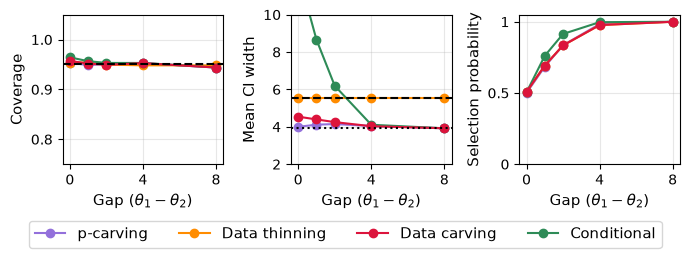

In [ ]:
# --- Plotting ---
labels = {
    'p-thinning': 'p-carving',
    'thinning': 'Data thinning',
    'csi': 'Conditional',
    'data_carving': 'Data carving',
}
colors = {
    'p-thinning': 'mediumpurple', #  'steelblue', actually p-carving
    'csi': 'seagreen',
    'thinning': 'darkorange',
    'data_carving': 'crimson',
}

fig, axes = plt.subplots(1, 3, figsize=(7, 2.3), sharex=True)

for k in results:
    axes[0].plot(mus_single, results[k]["coverage"], marker="o", label=labels[k], color=colors[k])
axes[0].axhline(1 - alpha_single, color="black", linestyle="--")
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim(0.75, 1.05)
axes[0].set_xlabel(r'Mean ($\theta_1$)', fontsize=11) # Mean (θ)
axes[0].set_ylabel("Coverage", fontsize=11)

for k in results:
    axes[1].plot(mus_single, results[k]["width"], marker="o", label=labels[k], color=colors[k])
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim(2, 10)
axes[1].axhline(2 * np.sqrt(2) * 1.96, linestyle='--', color='black')
axes[1].axhline(2 * 1.96, linestyle=':', color='black')    
axes[1].set_xlabel(r'Mean ($\theta_1$)', fontsize=11)
axes[1].set_ylabel("Mean CI width", fontsize=11)

for k in results:
    axes[2].plot(mus_single, results[k]["selection_prob"], marker="o", label=labels[k], color=colors[k])
axes[2].grid(True, alpha=0.3)
axes[2].set_ylim(0, 1.05)
axes[2].set_xlabel(r'Mean ($\theta_1$)', fontsize=11)
axes[2].set_ylabel("Selection probability", fontsize=11)
axes[2].set_yticks([0, 0.5, 1])
axes[2].set_yticklabels([0, 0.5, 1])

axes[2].set_xticks([0, 4, 8])
axes[2].set_xticklabels([0, 4, 8])


handles, legend_labels = axes[0].get_legend_handles_labels()
order = [0, 1, 3, 2]
fig.legend(
    [handles[o] for o in order],
    [legend_labels[o] for o in order],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.05),
    ncol=4,
    frameon=True,
    fontsize=11,
)

plt.tight_layout()
plt.savefig("../figures/winners_ci.png", dpi=300, bbox_inches="tight")
plt.show()